# Notebook 07 — Inverse Material Design & Cost-Constrained Candidate Ranking

**Purpose:** Rank existing DS-1 material records against configurable property and cost constraints using the latest available DS-5 element prices.

**Interpretation limits:** This is a constrained *screening/ranking* workflow, not a generative model and not experimental validation. Property values come from the supplied dataset; they are not newly predicted. The raw-element cost is an idealized composition-weighted input-cost proxy, excluding processing, energy, yield loss, transport, and lifecycle costs. Price coverage is required for every element in a formula. The dataset provenance remains unverified.

Outputs are written to `ML/outputs/notebook_07/` when run from the project, or to a local `outputs/notebook_07/` fallback.

In [8]:
from pathlib import Path
import os, re, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from rdkit import Chem

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)


In [9]:
# Locate the project data without hard-coding a Windows user path.
def find_file(filename):
    candidates = []
    env_root = os.environ.get("MATRISK_DATA_ROOT")
    if env_root:
        candidates.extend([Path(env_root) / filename, Path(env_root) / "raw" / filename])
    here = Path.cwd().resolve()
    for root in [here, *list(here.parents)[:5], Path("/mnt/data")]:
        candidates.extend([root / filename, root / "Data" / filename, root / "Data" / "raw" / filename,
                           root / "data" / "raw" / filename, root / "data" / "external" / filename])
    for candidate in candidates:
        if candidate.is_file():
            print(f"Found {filename}: {candidate.resolve()}")
            return candidate.resolve()
    raise FileNotFoundError(f"Could not find {filename}. Set MATRISK_DATA_ROOT or place it in Data/raw.")

DS1_PATH = find_file("DS1_material_properties_5500.csv")
DS5_PATH = find_file("DS5_element_prices_monthly.csv")
OUTPUT_DIR = Path.cwd().resolve() / "ML" / "outputs" / "notebook_07"
# If launched from ML/notebooks, project root is the parent of ML.
if Path.cwd().name == "notebooks" and Path.cwd().parent.name == "ML":
    OUTPUT_DIR = Path.cwd().parent / "outputs" / "notebook_07"
elif Path.cwd().name == "ML":
    OUTPUT_DIR = Path.cwd() / "outputs" / "notebook_07"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

materials = pd.read_csv(DS1_PATH)
prices = pd.read_csv(DS5_PATH, parse_dates=["date"])
print("DS-1:", materials.shape, "DS-5:", prices.shape)
required_material_cols = ["material_id", "formula", "formation_energy_per_atom_eV", "energy_above_hull_eV", "bulk_modulus_GPa", "shear_modulus_GPa", "density_g_cm3", "is_stable"]
required_price_cols = ["date", "element", "price_usd_per_kg"]
for col in required_material_cols:
    if col not in materials.columns:
        raise ValueError(f"DS-1 missing required column: {col}")
for col in required_price_cols:
    if col not in prices.columns:
        raise ValueError(f"DS-5 missing required column: {col}")


Found DS1_material_properties_5500.csv: C:\Users\Amey Ravindra Pandit\Downloads\MAT Risk\Data\raw\DS1_material_properties_5500.csv
Found DS5_element_prices_monthly.csv: C:\Users\Amey Ravindra Pandit\Downloads\MAT Risk\Data\raw\DS5_element_prices_monthly.csv
DS-1: (5500, 18) DS-5: (5280, 5)


In [10]:
# Parse simple flat formulas such as Al2O3, Ta3Au3H2, or Fe.
# Parentheses, dot hydrates, and unsupported syntax are flagged rather than guessed.
periodic_table = Chem.GetPeriodicTable()
TOKEN_RE = re.compile(r"([A-Z][a-z]?)([0-9]*)(?:$)")

def parse_flat_formula(formula):
    if not isinstance(formula, str) or not formula.strip():
        return None
    formula = formula.strip()
    # Require the entire formula to consist of element-symbol + optional integer tokens.
    parts = []
    pos = 0
    for match in re.finditer(r"([A-Z][a-z]?)([0-9]*)", formula):
        if match.start() != pos:
            return None
        symbol, count_txt = match.groups()
        atomic_num = periodic_table.GetAtomicNumber(symbol)
        if atomic_num <= 0:
            return None
        count = int(count_txt) if count_txt else 1
        if count <= 0:
            return None
        parts.append((symbol, count, float(periodic_table.GetAtomicWeight(atomic_num))))
        pos = match.end()
    if pos != len(formula) or not parts:
        return None
    total_mass = sum(count * weight for _, count, weight in parts)
    if total_mass <= 0:
        return None
    return {symbol: count * weight / total_mass for symbol, count, weight in parts}

parsed = materials["formula"].map(parse_flat_formula)
materials = materials.copy()
materials["_mass_fractions"] = parsed
materials["formula_parse_ok"] = parsed.notna()
print("Formula parsing:", int(materials["formula_parse_ok"].sum()), "/", len(materials))
display(materials[["material_id", "formula", "formula_parse_ok"]].head())


Formula parsing: 5500 / 5500


,material_id,formula,formula_parse_ok
0,mp-121959,Ta3Au3H2,True
1,mp-23248,Al3Rh4W3,True
2,mp-526982,Pd3Te3,True
3,mp-984775,Ne4Cd4,True
4,mp-965909,Al4Rh,True


In [11]:
# Use the latest available price for each element; do not fill missing elements with invented prices.
prices["element"] = prices["element"].astype(str).str.strip()
prices["price_usd_per_kg"] = pd.to_numeric(prices["price_usd_per_kg"], errors="coerce")
prices = prices.dropna(subset=["date", "element", "price_usd_per_kg"])
latest_date_by_element = prices.groupby("element")["date"].max()
latest_prices = (prices.sort_values("date").groupby("element", as_index=False).tail(1)
                 .set_index("element")["price_usd_per_kg"].to_dict())
latest_price_date = max(latest_date_by_element) if len(latest_date_by_element) else None
print("Latest price observation date across elements:", latest_price_date)
print("Elements with available prices:", len(latest_prices))

def estimate_raw_element_cost(mass_fractions):
    if not isinstance(mass_fractions, dict):
        return np.nan
    if not all(symbol in latest_prices for symbol in mass_fractions):
        return np.nan
    return float(sum(frac * latest_prices[symbol] for symbol, frac in mass_fractions.items()))

materials["raw_element_cost_proxy_usd_per_kg"] = materials["_mass_fractions"].map(estimate_raw_element_cost)
materials["price_coverage_complete"] = materials["raw_element_cost_proxy_usd_per_kg"].notna()
print("Complete-price-coverage materials:", int(materials["price_coverage_complete"].sum()), f"({materials['price_coverage_complete'].mean():.1%})")


Latest price observation date across elements: 2024-12-01 00:00:00
Elements with available prices: 40
Complete-price-coverage materials: 1795 (32.6%)


## Configure the screening constraints

These defaults are illustrative and can be edited. They are *filters*, not learned model outputs. A zero lower band-gap threshold includes metals; change it if you want semiconductors only.

In [12]:
# User-editable screening constraints
MIN_BULK_MODULUS_GPA = 40.0
MIN_SHEAR_MODULUS_GPA = 20.0
MAX_ENERGY_ABOVE_HULL_EV = 0.10
MAX_RAW_ELEMENT_COST_USD_PER_KG = None  # e.g. 100.0, or None to disable
MIN_BAND_GAP_EV = 0.0
MAX_BAND_GAP_EV = 3.0
REQUIRE_STABLE_LABEL = True

numeric_cols = ["formation_energy_per_atom_eV", "energy_above_hull_eV", "bulk_modulus_GPa", "shear_modulus_GPa", "density_g_cm3", "band_gap_eV", "is_stable"]
for col in numeric_cols:
    materials[col] = pd.to_numeric(materials[col], errors="coerce")

eligible = (
    materials["formula_parse_ok"]
    & materials["price_coverage_complete"]
    & materials["formation_energy_per_atom_eV"].notna()
    & materials["energy_above_hull_eV"].notna()
    & materials["bulk_modulus_GPa"].ge(MIN_BULK_MODULUS_GPA)
    & materials["shear_modulus_GPa"].ge(MIN_SHEAR_MODULUS_GPA)
    & materials["energy_above_hull_eV"].le(MAX_ENERGY_ABOVE_HULL_EV)
    & materials["band_gap_eV"].between(MIN_BAND_GAP_EV, MAX_BAND_GAP_EV, inclusive="both")
    & materials["density_g_cm3"].gt(0)
)
if REQUIRE_STABLE_LABEL:
    eligible &= materials["is_stable"].eq(1)
if MAX_RAW_ELEMENT_COST_USD_PER_KG is not None:
    eligible &= materials["raw_element_cost_proxy_usd_per_kg"].le(MAX_RAW_ELEMENT_COST_USD_PER_KG)

candidates = materials.loc[eligible].copy()
print(f"Candidates passing constraints: {len(candidates):,} / {len(materials):,}")


Candidates passing constraints: 647 / 5,500


In [13]:
# Transparent heuristic ranking: percentiles are relative to the eligible candidate pool.
# This is not a calibrated scientific utility function; adjust weights to your design objective.
def percentile_high(series):
    return series.rank(pct=True, method="average").fillna(0.0)
def percentile_low(series):
    return 1.0 - series.rank(pct=True, method="average").fillna(1.0)

if len(candidates):
    candidates["score_bulk"] = percentile_high(candidates["bulk_modulus_GPa"])
    candidates["score_shear"] = percentile_high(candidates["shear_modulus_GPa"])
    candidates["score_cost"] = percentile_low(candidates["raw_element_cost_proxy_usd_per_kg"])
    candidates["score_hull"] = percentile_low(candidates["energy_above_hull_eV"])
    candidates["heuristic_score_0_100"] = 100 * (
        0.35 * candidates["score_bulk"]
        + 0.30 * candidates["score_shear"]
        + 0.25 * candidates["score_cost"]
        + 0.10 * candidates["score_hull"]
    )
    candidates = candidates.sort_values(
        ["heuristic_score_0_100", "raw_element_cost_proxy_usd_per_kg"],
        ascending=[False, True]
    ).reset_index(drop=True)

output_cols = ["material_id", "formula", "crystal_system", "formation_energy_per_atom_eV", "energy_above_hull_eV", "band_gap_eV", "bulk_modulus_GPa", "shear_modulus_GPa", "density_g_cm3", "is_stable", "raw_element_cost_proxy_usd_per_kg", "heuristic_score_0_100"]
if len(candidates):
    display(candidates[output_cols].head(20))
else:
    print("No candidates satisfy all constraints. Relax filters only after reviewing the audit and intended design objective.")


,material_id,formula,crystal_system,formation_energy_per_atom_eV,energy_above_hull_eV,band_gap_eV,bulk_modulus_GPa,shear_modulus_GPa,density_g_cm3,is_stable,raw_element_cost_proxy_usd_per_kg,heuristic_score_0_100
0,mp-422638,Mg2,cubic,0.0000,0.0010,0.000,286.98,159.94,5.966,1,2.190000,93.825348
1,mp-221708,SiLi,tetragonal,-1.3297,0.0012,2.551,354.09,217.71,4.759,1,7.500532,93.516229
2,mp-58783,Fe4V,tetragonal,0.6179,0.0077,0.712,332.32,230.08,3.658,1,5.611081,92.078825
3,mp-90906,Mn3Ce3,cubic,-3.1463,0.0008,0.696,240.93,171.14,5.924,1,3.501340,91.097372
4,mp-61882,Pb2Si2,cubic,-0.0051,0.0161,1.199,315.87,178.70,5.030,1,2.221329,91.027821
5,mp-606162,Mg3,cubic,0.0000,0.0116,0.000,272.14,147.67,7.625,1,2.190000,89.714065
6,mp-954772,Mg4Ce,trigonal,-2.3867,0.0004,2.611,233.25,143.30,3.825,1,3.311703,89.350850
7,mp-628794,Al3Ti2,cubic,-1.1011,0.0007,0.000,240.19,163.27,1.864,1,6.550612,88.894900
8,mp-134996,Ni,monoclinic,0.3653,0.0110,0.460,423.05,178.62,2.911,1,17.920000,87.870943
9,mp-38649,Fe3Ce4,cubic,0.3304,0.0134,0.516,318.82,118.47,6.356,1,3.169477,86.939722


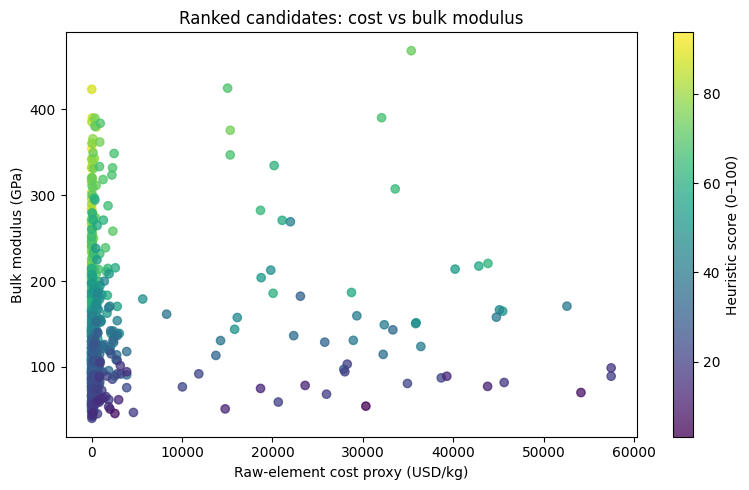

{
  "ds1_rows": 5500,
  "formula_parse_success_rows": 5500,
  "elements_with_latest_prices": 40,
  "latest_price_date_across_elements": "2024-12-01",
  "complete_price_coverage_rows": 1795,
  "complete_price_coverage_fraction": 0.32636363636363636,
  "candidates_passing_constraints": 647,
  "constraints": {
    "min_bulk_modulus_GPa": 40.0,
    "min_shear_modulus_GPa": 20.0,
    "max_energy_above_hull_eV": 0.1,
    "max_raw_element_cost_usd_per_kg": null,
    "band_gap_eV_range": [
      0.0,
      3.0
    ],
    "require_stable_label": true
  },
  "ranking_weights": {
    "bulk": 0.35,
    "shear": 0.3,
    "cost": 0.25,
    "energy_above_hull": 0.1
  },
  "limitations": [
    "Ranks existing dataset records; does not generate new chemical compositions.",
    "Property values are supplied dataset values, not newly predicted or experimentally verified.",
    "Cost is a composition-weighted raw-element price proxy, not manufacturing or lifecycle cost.",
    "Formula parser only accepts 

In [14]:
# Export reproducible candidate tables and coverage diagnostics.
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
all_costs_path = OUTPUT_DIR / "material_cost_coverage.csv"
materials[["material_id", "formula", "formula_parse_ok", "price_coverage_complete", "raw_element_cost_proxy_usd_per_kg"]].to_csv(all_costs_path, index=False)
candidates_path = OUTPUT_DIR / "ranked_material_candidates.csv"
candidates[output_cols].to_csv(candidates_path, index=False)

coverage_by_element = pd.DataFrame({"element": sorted(latest_prices), "latest_price_usd_per_kg": [latest_prices[e] for e in sorted(latest_prices)]})
coverage_by_element["latest_price_date"] = latest_price_date
coverage_by_element.to_csv(OUTPUT_DIR / "latest_element_prices_used.csv", index=False)

if len(candidates):
    fig, ax = plt.subplots(figsize=(8, 5))
    sc = ax.scatter(candidates["raw_element_cost_proxy_usd_per_kg"], candidates["bulk_modulus_GPa"], c=candidates["heuristic_score_0_100"], alpha=0.75)
    ax.set_xlabel("Raw-element cost proxy (USD/kg)")
    ax.set_ylabel("Bulk modulus (GPa)")
    ax.set_title("Ranked candidates: cost vs bulk modulus")
    fig.colorbar(sc, ax=ax, label="Heuristic score (0–100)")
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / "candidate_cost_vs_bulk_modulus.png", dpi=140)
    plt.show()

summary = {
    "ds1_rows": int(len(materials)),
    "formula_parse_success_rows": int(materials["formula_parse_ok"].sum()),
    "elements_with_latest_prices": int(len(latest_prices)),
    "latest_price_date_across_elements": str(latest_price_date.date()) if latest_price_date is not None else None,
    "complete_price_coverage_rows": int(materials["price_coverage_complete"].sum()),
    "complete_price_coverage_fraction": float(materials["price_coverage_complete"].mean()),
    "candidates_passing_constraints": int(len(candidates)),
    "constraints": {
        "min_bulk_modulus_GPa": MIN_BULK_MODULUS_GPA,
        "min_shear_modulus_GPa": MIN_SHEAR_MODULUS_GPA,
        "max_energy_above_hull_eV": MAX_ENERGY_ABOVE_HULL_EV,
        "max_raw_element_cost_usd_per_kg": MAX_RAW_ELEMENT_COST_USD_PER_KG,
        "band_gap_eV_range": [MIN_BAND_GAP_EV, MAX_BAND_GAP_EV],
        "require_stable_label": REQUIRE_STABLE_LABEL,
    },
    "ranking_weights": {"bulk": 0.35, "shear": 0.30, "cost": 0.25, "energy_above_hull": 0.10},
    "limitations": [
        "Ranks existing dataset records; does not generate new chemical compositions.",
        "Property values are supplied dataset values, not newly predicted or experimentally verified.",
        "Cost is a composition-weighted raw-element price proxy, not manufacturing or lifecycle cost.",
        "Formula parser only accepts flat formulas; unsupported syntax is flagged.",
        "Ranking score is a heuristic and not a calibrated physical utility function.",
        "Dataset provenance and price source provenance are not independently verified."
    ],
    "outputs": [str(all_costs_path), str(candidates_path), str(OUTPUT_DIR / "latest_element_prices_used.csv")]
}
with open(OUTPUT_DIR / "run_summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2)
print(json.dumps(summary, indent=2))
print("Output directory:", OUTPUT_DIR.resolve())
